# Лабораторна робота №8 — Метод головних компонент (PCA)
### Проєкт DocVerify — пояснена дисперсія, візуалізація у 2D та вплив зниження розмірності на класифікатор

**Ланцюжок роботи:** стандартизація даних → PCA → пояснена дисперсія → вибір компонент →
візуалізація PC1 та PC2 → класифікація → порівняння результатів → висновок.

**Як запустити.** Потрібні `numpy`, `pandas`, `matplotlib`, `scikit-learn`, а також `ipywidgets`
і `plotly` (`pip install ipywidgets plotly`). Виконайте всі комірки (*Run All*): сторінка
лабораторної роботи з кнопкою **«Запустити аналіз»** розташована в останній комірці. Усі
числа, графіки й висновки обчислюються під час запуску; збережений вивід останньої комірки —
це результат фактичного виконання, а не заготовка.

## Конфігурація

Простір ознак і параметри класифікатора ті самі, що в Лаб. №2–7, щоб експеримент A був
порівнянним із попередніми результатами.

In [1]:
import os
import json
import time
import base64
import warnings
from io import BytesIO
from html import escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import HTML, display

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, adjusted_rand_score, f1_score, precision_score,
                             recall_score, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# ==================== КОНФІГУРАЦІЙНИЙ БЛОК ====================
FEATURES_CSV = "data/features_lab2.csv"
OUTPUT_DIR = "outputs"
TARGET = "document_type"                  # цільова змінна: тип документа (20 класів)
AUTH_COLUMN = "authenticity"
SOURCE_COLUMN = "source_dataset"
RANDOM_STATE = 42
TEST_SIZE = 0.2

# Простір ознак із Лаб. №2–7 (6 числових + One-Hot для 2 категоріальних)
NUMERIC_COLS = ['width', 'height', 'file_size_bytes', 'aspect_ratio',
                'std_brightness', 'dark_pixel_ratio']
CATEGORICAL_COLS = [SOURCE_COLUMN, AUTH_COLUMN]
CAPPED_COLS = ['width', 'file_size_bytes']   # capping викидів за IQR, як у Лаб. №2

EXCLUDED_FIELDS = {
    'filename': 'ідентифікатор об\'єкта, не несе ознакової інформації',
    TARGET: 'цільова змінна — не входить до матриці ознак',
    'mean_brightness': 'вилучена в Лаб. №2 (r ≈ −0.95 з dark_pixel_ratio)',
    'color_saturation_mean': 'не входить до простору ознак, на якому оцінювалися моделі Лаб. №3–7',
}

# Найкращий класифікатор попередніх робіт (довідкові значення зі збережених результатів
# Лаб. №6 і №7; це не результати цієї роботи, вони потрібні лише для обґрунтування вибору
# та звірки відтворюваності експерименту A).
BEST_CLASSIFIER_NAME = 'k-NN (k=21, euclidean, uniform)'
BEST_CLASSIFIER = KNeighborsClassifier(n_neighbors=21, metric='euclidean', weights='uniform')
PREVIOUS_RESULTS = pd.DataFrame([
    ('k-NN (k=21)', 'Лаб. №3', 0.3962, 0.4084, 0.3786),
    ('GaussianNB', 'Лаб. №4', 0.3297, 0.3053, 0.3229),
    ('Decision Tree (GridSearch)', 'Лаб. №5', 0.3677, 0.3532, 0.3542),
    ('Logistic Regression (C=1.0)', 'Лаб. №6', 0.3514, 0.3293, 0.3396),
], columns=['Модель', 'Робота', 'Test Accuracy', 'Test F1-macro', 'CV Accuracy (Лаб. №7)'])

VARIANCE_THRESHOLDS = (0.90, 0.95)
TIMING_REPEATS = 15              # час — медіана повторних вимірювань
ACCURACY_TOLERANCE = 0.01        # зміна до 1 в. п. вважається «майже незмінною»
MIN_OBJECTS_PER_CLASS = 5        # щоб після розбиття 80/20 клас був і в train, і в test
MIN_CLASSES = 2

# Режим збереження звіту: комірка сторінки виконує аналіз без натискання кнопки.
AUTO_RUN = os.environ.get('DOCVERIFY_LAB8_AUTORUN') == '1'
# ================================================================

SERIES_COLORS = {'full': '#2a78d6', 'pca': '#eb6834'}
NEUTRAL = {'ink': '#0b0b0b', 'muted': '#52514e', 'grid': '#e4e3df', 'threshold': '#6f6e69'}
# 20 класів неможливо розрізнити лише кольором, тому клас кодується парою «колір + форма»
CLASS_HUES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
CLASS_MARKERS = [('o', 'circle'), ('s', 'square'), ('^', 'triangle-up')]

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': NEUTRAL['grid'], 'axes.labelcolor': NEUTRAL['muted'],
    'text.color': NEUTRAL['ink'], 'xtick.color': NEUTRAL['muted'], 'ytick.color': NEUTRAL['muted'],
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': NEUTRAL['grid'], 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})


class InsufficientDataError(Exception):
    """Реальних даних із визначеними класами недостатньо для коректного аналізу."""

## 1. Підготовка та стандартизація даних

* **Ознаки:** 6 числових і One-Hot-стовпці `source_dataset` та `authenticity` — разом 13.
* **Цільова змінна:** `document_type`; вона та `filename` до матриці ознак не входять.
* **Пропуски:** `authenticity` заповнюється категорією `not_applicable` (рішення Лаб. №2);
  рядки без класу або з пропусками в числових ознаках виключаються й підраховуються.
* **Без витоку:** межі capping, `OneHotEncoder` і `StandardScaler` навчаються через одну
  функцію `fit_preprocessor`. Для класифікації вона отримує лише train. У Лаб. №2–7 межі
  capping рахувалися на всьому наборі; тут цю неточність усунено.

In [2]:
def load_dataset(path=FEATURES_CSV):
    """Завантажує дані проєкту та перевіряє, чи їх достатньо для аналізу."""
    if not os.path.exists(path):
        raise InsufficientDataError(f'Файл набору даних не знайдено: {path}. '
                                    'Спершу виконайте Лаб. №2, яка його формує.')
    raw = pd.read_csv(path)

    required = set(NUMERIC_COLS) | set(CATEGORICAL_COLS) | {TARGET}
    missing_columns = sorted(required - set(raw.columns))
    if missing_columns:
        raise InsufficientDataError('У наборі даних бракує стовпців: ' + ', '.join(missing_columns))

    missing_by_column = raw[sorted(required)].isna().sum()
    df = raw.copy()
    df[NUMERIC_COLS] = df[NUMERIC_COLS].replace([np.inf, -np.inf], np.nan)
    df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna('not_applicable')
    usable = df[TARGET].notna() & df[NUMERIC_COLS].notna().all(axis=1) & df[SOURCE_COLUMN].notna()
    df = df[usable].reset_index(drop=True)

    class_counts = df[TARGET].value_counts()
    if len(class_counts) < MIN_CLASSES:
        raise InsufficientDataError(f'Знайдено класів: {len(class_counts)}. Для розфарбовування '
                                    f'та класифікації потрібно щонайменше {MIN_CLASSES}.')
    rare = class_counts[class_counts < MIN_OBJECTS_PER_CLASS]
    if len(rare):
        raise InsufficientDataError(
            f'Класи з менш ніж {MIN_OBJECTS_PER_CLASS} об\'єктами: '
            + ', '.join(f'{name} ({count})' for name, count in rare.items())
            + '. Коректне стратифіковане розбиття неможливе.')
    n_train = int(len(df) * (1 - TEST_SIZE))
    if n_train <= BEST_CLASSIFIER.n_neighbors:
        raise InsufficientDataError(f'Об\'єктів у train: {n_train}. Для k-NN потрібно більше ніж '
                                    f'{BEST_CLASSIFIER.n_neighbors}.')

    info = {
        'n_rows_raw': len(raw), 'n_rows': len(df), 'n_excluded': len(raw) - len(df),
        'missing_by_column': missing_by_column[missing_by_column > 0],
        'class_counts': class_counts,
        'source_classes': df.groupby(SOURCE_COLUMN)[TARGET].agg(['size', 'nunique']),
    }
    return df, info


def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def fit_preprocessor(df_fit):
    """Навчає всі перетворення ознак ЛИШЕ на переданій частині даних."""
    bounds = {col: iqr_bounds(df_fit[col]) for col in CAPPED_COLS}
    encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    encoder.fit(df_fit[CATEGORICAL_COLS])
    scaler = StandardScaler()
    prep = {'bounds': bounds, 'encoder': encoder, 'scaler': scaler}
    scaler.fit(build_matrix(df_fit, prep))
    return prep


def build_matrix(df, prep):
    numeric = df[NUMERIC_COLS].astype(float).copy()
    for col, (low, high) in prep['bounds'].items():
        numeric[col] = numeric[col].clip(low, high)
    return np.hstack([numeric.values, prep['encoder'].transform(df[CATEGORICAL_COLS])])


def transform_scaled(df, prep):
    return prep['scaler'].transform(build_matrix(df, prep))


def feature_names(prep):
    encoded = prep['encoder'].get_feature_names_out(CATEGORICAL_COLS)
    return NUMERIC_COLS + [name.split(' (')[0] for name in encoded]

## 2. Частина 1 — пояснена дисперсія та вибір компонент

`PCA()` без обмеження кількості компонент застосовується до всього набору: це описовий аналіз
структури даних. Для класифікації (частина 3) усе повторюється окремо лише на train.

In [3]:
def components_for_threshold(cumulative_variance, threshold):
    return int(np.argmax(cumulative_variance >= threshold) + 1)


def analyze_variance(X_scaled):
    pca = PCA().fit(X_scaled)
    ratio = pca.explained_variance_ratio_
    cumulative = np.cumsum(ratio)
    selected = {t: components_for_threshold(cumulative, t) for t in VARIANCE_THRESHOLDS}
    return {'ratio': ratio, 'cumulative': cumulative, 'selected': selected}

## 3. Частина 2 — візуалізація у просторі двох компонент

`PCA(n_components=2).fit_transform()` дає координати кожного об'єкта. Опис під діаграмою
формується з обчислених показників:
* **силует за класами** — наскільки об'єкт ближчий до свого класу, ніж до сусіднього;
* **чистота сусідства** — частка об'єктів того самого класу серед 15 найближчих у площині;
* **KMeans + скоригований індекс Ренда** — чи є окремі групи й чому вони відповідають:
  типу документа чи джерелу даних.

In [4]:
NEIGHBOURS_FOR_PURITY = 15


def top_loadings(component, names, n=3):
    order = np.argsort(np.abs(component))[::-1][:n]
    return [f'{names[i]} ({component[i]:+.2f})' for i in order]


def analyze_projection(X_scaled, y, class_names, sources, names):
    pca2 = PCA(n_components=2)
    Z = pca2.fit_transform(X_scaled)

    neighbours = NearestNeighbors(n_neighbors=NEIGHBOURS_FOR_PURITY + 1).fit(Z)
    indices = neighbours.kneighbors(Z, return_distance=False)
    same_class = (y[indices] == y[:, None])
    is_self = indices == np.arange(len(Z))[:, None]
    purity_per_object = (same_class & ~is_self).sum(axis=1) / NEIGHBOURS_FOR_PURITY
    purity_by_class = (pd.Series(purity_per_object).groupby(class_names[y]).mean()
                       .sort_values(ascending=False))

    clusterings = {k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
                   for k in range(2, 9)}
    cluster_scores = {k: silhouette_score(Z, labels) for k, labels in clusterings.items()}
    best_k = max(cluster_scores, key=cluster_scores.get)

    return {
        'Z': Z,
        'share': float(pca2.explained_variance_ratio_.sum()),
        'pc_ratio': pca2.explained_variance_ratio_,
        'silhouette_classes': float(silhouette_score(Z, y)),
        'purity_mean': float(purity_per_object.mean()),
        'purity_by_class': purity_by_class,
        'best_k': best_k,
        'cluster_silhouette': float(cluster_scores[best_k]),
        'ari_class': float(adjusted_rand_score(y, clusterings[best_k])),
        'ari_source': float(adjusted_rand_score(sources, clusterings[best_k])),
        'loadings': [top_loadings(pca2.components_[i], names) for i in range(2)],
    }


def describe_projection(p, n_classes):
    """Опис діаграми на основі фактичних показників; пороги — загальноприйнята шкала силуету."""
    sil = p['silhouette_classes']
    if sil >= 0.5:
        separation = 'класи розділяються чітко'
    elif sil >= 0.25:
        separation = 'класи розділяються частково'
    elif sil >= 0:
        separation = 'більшість класів не розділяється'
    else:
        separation = 'класи загалом не розділяються: об\'єкти часто ближчі до чужих класів, ніж до свого'
    best = p['purity_by_class']
    separated = best[best >= 0.7]
    separated_text = (f'Виразно відокремлені: {", ".join(separated.index)}.' if len(separated)
                      else 'Жоден клас не має чистоти сусідства від 70%.')
    answers = [(
        'Чи розділяються класи у просторі PC1–PC2?',
        f'{separation.capitalize()} (силует за класами {sil:.3f}). {separated_text}'
    ), (
        'Чи спостерігається перетин класів?',
        f'{"Так" if p["purity_mean"] < 0.7 else "Незначний"}: серед {NEIGHBOURS_FOR_PURITY} найближчих '
        f'сусідів у середньому {p["purity_mean"]:.1%} належать до того самого класу (за випадкового '
        f'розташування близько {1 / n_classes:.0%}). Найсильніше змішані: '
        f'{", ".join(best.index[-3:][::-1])}.'
    )]
    if p['cluster_silhouette'] >= 0.5:
        relation = ('вони більше відповідають джерелу даних, ніж типу документа'
                    if p['ari_source'] > p['ari_class']
                    else 'вони більше відповідають типу документа, ніж джерелу даних')
        groups = (f'Так, KMeans найкраще ділить дані за k={p["best_k"]} (силует '
                  f'{p["cluster_silhouette"]:.3f}), але {relation} (ARI: джерело '
                  f'{p["ari_source"]:.3f}, тип документа {p["ari_class"]:.3f}).')
    else:
        groups = (f'Виразних окремих груп немає: найкраще розбиття KMeans (k={p["best_k"]}) має '
                  f'силует лише {p["cluster_silhouette"]:.3f}.')
    answers.append(('Чи можна побачити окремі групи?', groups))
    share = p['share']
    quality = 'добре' if share >= 0.7 else ('лише частково' if share >= 0.4 else 'слабко')
    answers.append((
        'Наскільки добре перші дві компоненти відображають структуру даних?',
        f'{quality.capitalize()}: PC1 і PC2 разом пояснюють {share:.1%} дисперсії '
        f'({p["pc_ratio"][0]:.1%} + {p["pc_ratio"][1]:.1%}), тож решта структури в площині не видна. '
        f'PC1 формують {", ".join(p["loadings"][0])}; PC2 — {", ".join(p["loadings"][1])}.'
    ))
    return answers

## 4. Частина 3 — класифікація на зменшеному наборі ознак

Обидва експерименти використовують той самий поділ train/test, той самий клас моделі з тими
самими параметрами та `random_state`.

* **A:** `fit_preprocessor(train)` → k-NN на всіх ознаках.
* **B:** той самий preprocessor → `PCA` навчається лише на train → кількість компонент
  для ≥90% дисперсії визначається за train → test лише проходить через `transform()`.

Час вимірюється `time.perf_counter()` як медіана `TIMING_REPEATS` повторів, бо окремий вимір
для k-NN (мілісекунди) надто шумний. Метрики усереднені за класами (macro), бо класи не
зовсім збалансовані, і саме `F1-macro` використовувалася в попередніх роботах.

In [5]:
def timed(function):
    """Повертає результат останнього виклику та медіанний час виконання, с."""
    durations, result = [], None
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        result = function()
        durations.append(time.perf_counter() - start)
    return result, float(np.median(durations))


def evaluate_classifier(X_train, y_train, X_test, y_test):
    model, fit_time = timed(lambda: clone(BEST_CLASSIFIER).fit(X_train, y_train))
    y_pred, predict_time = timed(lambda: model.predict(X_test))
    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'f1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'f1_weighted': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'fit_time': fit_time,
        'predict_time': predict_time,
        'n_features': X_train.shape[1],
    }


def run_classification(df, y):
    train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE,
                                           random_state=RANDOM_STATE, stratify=y)
    df_train, df_test = df.loc[train_idx], df.loc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    prep = fit_preprocessor(df_train)
    X_train = transform_scaled(df_train, prep)
    X_test = transform_scaled(df_test, prep)

    full = evaluate_classifier(X_train, y_train, X_test, y_test)

    train_variance = analyze_variance(X_train)
    n_components = train_variance['selected'][0.90]
    (pca, X_train_pca), pca_fit_time = timed(lambda: fit_pca(X_train, n_components))
    X_test_pca, pca_transform_time = timed(lambda: pca.transform(X_test))
    reduced = evaluate_classifier(X_train_pca, y_train, X_test_pca, y_test)
    reduced.update(pca_fit_time=pca_fit_time, pca_transform_time=pca_transform_time,
                   retained_variance=float(pca.explained_variance_ratio_.sum()))

    return {'full': full, 'pca': reduced, 'n_train': len(train_idx), 'n_test': len(test_idx),
            'train_variance': train_variance, 'changes': compute_changes(full, reduced)}


def fit_pca(X_train, n_components):
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    return pca, pca.fit_transform(X_train)


def relative_change(before, after):
    return (after - before) / before * 100 if before else float('nan')


def compute_changes(full, reduced):
    fit_with_pca = reduced['fit_time'] + reduced['pca_fit_time']
    cycle_full = full['fit_time'] + full['predict_time']
    cycle_pca = (fit_with_pca + reduced['pca_transform_time'] + reduced['predict_time'])
    return {
        'features_reduction_pct': -relative_change(full['n_features'], reduced['n_features']),
        'accuracy_delta': reduced['accuracy'] - full['accuracy'],
        'accuracy_rel': relative_change(full['accuracy'], reduced['accuracy']),
        'f1_delta': reduced['f1'] - full['f1'],
        'f1_rel': relative_change(full['f1'], reduced['f1']),
        'fit_time_rel': relative_change(full['fit_time'], reduced['fit_time']),
        'predict_time_rel': relative_change(full['predict_time'], reduced['predict_time']),
        'cycle_full': cycle_full, 'cycle_pca': cycle_pca,
        'cycle_rel': relative_change(cycle_full, cycle_pca),
    }

## 5. Автоматичний висновок

Кожна теза будується з фактичних результатів запуску: формулювання обирається за знаком
і величиною змін, а не задається заздалегідь.

In [6]:
def change_verb(delta, feminine=True):
    if abs(delta) <= ACCURACY_TOLERANCE:
        return 'майже не змінилася' if feminine else 'майже не змінився'
    if delta < 0:
        return 'знизилася' if feminine else 'знизився'
    return 'зросла' if feminine else 'зріс'


def time_verb(rel):
    if abs(rel) < 5:
        return 'практично не змінився'
    return 'скоротився' if rel < 0 else 'збільшився'


def build_conclusion(res):
    cl = res['classification']
    full, reduced, ch = cl['full'], cl['pca'], cl['changes']
    selected = res['variance']['selected']
    cumulative = res['variance']['cumulative']
    k90, k95 = selected[0.90], selected[0.95]
    n_features = res['n_features']
    n_test = cl['n_test']
    lost_objects = abs(round(ch['accuracy_delta'] * n_test))

    points = [
        f'Для збереження 90% дисперсії потрібно <b>{k90}</b> компонент із {n_features} '
        f'(фактично {cumulative[k90 - 1]:.2%}).',
        f'Для збереження 95% дисперсії потрібно <b>{k95}</b> компонент '
        f'(фактично {cumulative[k95 - 1]:.2%}).',
        f'У класифікаційному експерименті розмірність зменшилася з {full["n_features"]} до '
        f'{reduced["n_features"]} ознак, тобто на <b>{ch["features_reduction_pct"]:.1f}%</b>; '
        f'компоненти зберігають {reduced["retained_variance"]:.2%} дисперсії train.',
        f'Accuracy {change_verb(ch["accuracy_delta"])}: {full["accuracy"]:.4f} → '
        f'{reduced["accuracy"]:.4f} ({ch["accuracy_delta"] * 100:+.2f} в. п., '
        f'{ch["accuracy_rel"]:+.1f}%), це приблизно {lost_objects} із {n_test} тестових об\'єктів.',
        f'F1-score (macro) {change_verb(ch["f1_delta"], feminine=False)}: {full["f1"]:.4f} → {reduced["f1"]:.4f} '
        f'({ch["f1_delta"] * 100:+.2f} в. п., {ch["f1_rel"]:+.1f}%).',
        f'Час навчання класифікатора {time_verb(ch["fit_time_rel"])}: '
        f'{full["fit_time"] * 1000:.3f} → {reduced["fit_time"] * 1000:.3f} мс '
        f'({ch["fit_time_rel"]:+.1f}%). Час передбачення {time_verb(ch["predict_time_rel"])}: '
        f'{full["predict_time"] * 1000:.2f} → {reduced["predict_time"] * 1000:.2f} мс '
        f'({ch["predict_time_rel"]:+.1f}%). Разом із навчанням і застосуванням PCA '
        f'({reduced["pca_fit_time"] * 1000:.3f} + {reduced["pca_transform_time"] * 1000:.3f} мс) '
        f'повний цикл становить {ch["cycle_pca"] * 1000:.2f} мс проти '
        f'{ch["cycle_full"] * 1000:.2f} мс без PCA ({ch["cycle_rel"]:+.1f}%).',
        recommendation(ch, reduced, full),
    ]
    return points


def recommendation(ch, reduced, full):
    quality_lost = max(-ch['accuracy_delta'], -ch['f1_delta'])
    faster = ch['cycle_rel'] < -5
    k = reduced['n_features']
    if quality_lost <= ACCURACY_TOLERANCE:
        benefit = (f'Точність майже не змінилася, а ознак стало {k} замість {full["n_features"]}: '
                   'модель простіша, а k-NN зберігає менше даних про навчальні об\'єкти')
        benefit += ', і цикл обчислень швидший.' if faster else '.'
        return f'<b>PCA доцільно застосовувати.</b> {benefit}'
    if faster:
        saved_ms = abs(ch['cycle_full'] - ch['cycle_pca']) * 1000
        scale_note = ('Абсолютний виграш менший за секунду, тому за пріоритету точності варто '
                      'залишити повний набір, а PCA використовувати для візуалізації.'
                      if saved_ms < 1000 else
                      'Абсолютний виграш відчутний, тому PCA виправданий там, де швидкість '
                      'важливіша за втрачену якість.')
        return (f'<b>PCA доцільно застосовувати лише як компроміс.</b> Втрата до '
                f'{quality_lost * 100:.2f} в. п. якості обмінюється на прискорення циклу на '
                f'{abs(ch["cycle_rel"]):.1f}% ({saved_ms:.2f} мс на весь test). PCA відкидає напрями '
                f'з малою дисперсією, але для розрізнення класів вони можуть бути корисними. {scale_note}')
    return (f'<b>Для класифікації PCA недоцільний.</b> Якість знизилася до '
            f'{quality_lost * 100:.2f} в. п., а помітного виграшу в часі немає. PCA варто залишити '
            'для візуалізації та аналізу структури даних.')

## Запуск повного аналізу

In [7]:
def run_analysis(path=FEATURES_CSV, progress=lambda message: None):
    progress('Крок 1/4: завантаження та підготовка даних')
    df, info = load_dataset(path)
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(df[TARGET])
    class_names = label_encoder.classes_

    prep_all = fit_preprocessor(df)
    X_scaled = transform_scaled(df, prep_all)
    names = feature_names(prep_all)

    progress('Крок 2/4: PCA та пояснена дисперсія')
    variance = analyze_variance(X_scaled)

    progress('Крок 3/4: проєкція на PC1–PC2')
    sources = df[SOURCE_COLUMN].to_numpy()
    projection = analyze_projection(X_scaled, y, class_names, sources, names)

    progress('Крок 4/4: експерименти A і B (повний набір та PCA)')
    classification = run_classification(df, y)

    result = {
        'df': df, 'info': info, 'y': y, 'class_names': class_names, 'feature_names': names,
        'n_features': X_scaled.shape[1], 'variance': variance, 'projection': projection,
        'classification': classification,
    }
    result['projection_answers'] = describe_projection(projection, len(class_names))
    result['conclusion'] = build_conclusion(result)
    return result

## Побудова сторінки: графіки, таблиці, блоки

In [8]:
def show_figure(fig, filename):
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    fig.savefig(os.path.join(OUTPUT_DIR, filename), dpi=130, bbox_inches='tight')
    display(fig)
    plt.close(fig)


def heading(number, title):
    display(HTML(f'<h3 style="margin:22px 0 6px">{number}. {escape(title)}</h3>'))


def paragraph(html, muted=False):
    color = f'color:{NEUTRAL["muted"]};' if muted else ''
    display(HTML(f'<p style="{color}max-width:880px;line-height:1.5">{html}</p>'))


def show_table(rows, columns):
    frame = pd.DataFrame(rows, columns=columns)
    display(HTML(frame.to_html(index=False, escape=True, border=0, classes='lab8-table')))


def plot_individual_variance(variance):
    ratio = variance['ratio']
    x = np.arange(1, len(ratio) + 1)
    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(x, ratio, width=0.62, color=SERIES_COLORS['full'])
    for bar, value in zip(bars, ratio):
        if value >= 0.01:
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.006, f'{value:.3f}',
                    ha='center', fontsize=9, color=NEUTRAL['muted'])
    ax.set_xticks(x)
    ax.set_xlabel('Номер головної компоненти')
    ax.set_ylabel('Частка поясненої дисперсії')
    ax.set_title('Частка поясненої дисперсії кожної компоненти')
    ax.grid(axis='x', visible=False)
    show_figure(fig, 'fig_lab8_explained_variance.png')


def plot_cumulative_variance(variance):
    cumulative = variance['cumulative'] * 100
    x = np.arange(1, len(cumulative) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.plot(x, cumulative, color=SERIES_COLORS['full'], linewidth=2, marker='o', markersize=5)
    label_offsets = {0.90: (-12, -46), 0.95: (12, -46)}
    for threshold, k in variance['selected'].items():
        level = threshold * 100
        ax.hlines(level, 0.5, len(x) + 0.3, color=NEUTRAL['threshold'], linestyle='--', linewidth=1)
        ax.text(len(x) + 0.4, level, f'{level:.0f}%', va='center', fontsize=9,
                color=NEUTRAL['muted'])
        ax.vlines(k, 0, cumulative[k - 1], color=NEUTRAL['threshold'], linestyle=':', linewidth=1)
        ax.scatter([k], [cumulative[k - 1]], s=80, zorder=3, color=SERIES_COLORS['pca'],
                   edgecolor='white', linewidth=1.5)
        ax.annotate(f'k = {k}\n{cumulative[k - 1]:.1f}%', (k, cumulative[k - 1]),
                    xytext=label_offsets[threshold], textcoords='offset points',
                    ha='right' if threshold == 0.90 else 'left', fontsize=9)
    ax.set_xticks(x)
    ax.set_xlim(0.5, len(x) + 1)
    ax.set_ylim(0, 103)
    ax.set_xlabel('Кількість компонент')
    ax.set_ylabel('Накопичена пояснена дисперсія, %')
    ax.set_title('Накопичена пояснена дисперсія та пороги 90% і 95%')
    ax.grid(axis='x', visible=False)
    show_figure(fig, 'fig_lab8_cumulative_variance.png')


def class_style(index):
    hue = CLASS_HUES[index % len(CLASS_HUES)]
    marker = CLASS_MARKERS[index // len(CLASS_HUES) % len(CLASS_MARKERS)]
    return hue, marker


def plot_projection_static(Z, y, class_names):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for index, name in enumerate(class_names):
        hue, (marker, _) = class_style(index)
        mask = y == index
        ax.scatter(Z[mask, 0], Z[mask, 1], s=22, c=hue, marker=marker, alpha=0.65,
                   edgecolors='white', linewidths=0.3, label=name)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title('Об\'єкти DocVerify у просторі PC1–PC2 за типом документа')
    ax.legend(title='Тип документа', loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False,
              fontsize=9, markerscale=1.3)
    return fig


def plotly_payload(Z, y, df, class_names):
    """Інтерактивна версія: у підказках лише безпечні атрибути, без шляхів та вмісту файлів."""
    fig = go.Figure()
    for index, name in enumerate(class_names):
        hue, (_, symbol) = class_style(index)
        mask = y == index
        subset = df[mask]
        custom = [[f'#{row_id}', source.split(' (')[0], int(width), int(height)]
                  for row_id, source, width, height in zip(subset.index, subset[SOURCE_COLUMN],
                                                           subset['width'], subset['height'])]
        fig.add_trace(go.Scatter(
            x=np.round(Z[mask, 0], 3).tolist(), y=np.round(Z[mask, 1], 3).tolist(),
            mode='markers', name=name, customdata=custom,
            marker=dict(color=hue, symbol=symbol, size=7, opacity=0.7,
                        line=dict(color='white', width=0.5)),
            hovertemplate=(f'<b>{name}</b><br>Об\'єкт %{{customdata[0]}}<br>'
                           'Джерело: %{customdata[1]}<br>'
                           'Розмір: %{customdata[2]}×%{customdata[3]} пкс<br>'
                           'PC1: %{x:.2f}, PC2: %{y:.2f}<extra></extra>'),
        ))
    fig.update_layout(
        title='Об\'єкти DocVerify у просторі PC1–PC2 за типом документа',
        xaxis_title='PC1', yaxis_title='PC2', legend_title_text='Тип документа',
        template='plotly_white', height=620, margin=dict(t=60, r=20, b=50, l=60),
    )
    return json.loads(fig.to_json())


def show_projection(res):
    """Підказки доступні у фронтендах із підтримкою Plotly; інакше показується той самий PNG."""
    p, y, class_names = res['projection'], res['y'], res['class_names']
    static = plot_projection_static(p['Z'], y, class_names)
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    static.savefig(os.path.join(OUTPUT_DIR, 'fig_lab8_pc1_pc2.png'), dpi=130, bbox_inches='tight')
    buffer = BytesIO()
    static.savefig(buffer, format='png', dpi=100, bbox_inches='tight')
    plt.close(static)
    display({
        'application/vnd.plotly.v1+json': plotly_payload(p['Z'], y, res['df'], class_names),
        'image/png': base64.b64encode(buffer.getvalue()).decode('ascii'),
        'text/plain': 'Діаграма PC1–PC2',
    }, raw=True)


def plot_comparison(cl):
    full, reduced = cl['full'], cl['pca']
    panels = [
        ('accuracy', 'Accuracy', 'Accuracy', 1, '{:.4f}'),
        ('f1', 'F1-score (macro)', 'F1-score', 1, '{:.4f}'),
        ('fit_time', 'Час навчання класифікатора', 'мс', 1000, '{:.3f} мс'),
        ('n_features', 'Кількість ознак', 'ознак', 1, '{:.0f}'),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.4))
    for ax, (key, title, ylabel, scale, template) in zip(axes.ravel(), panels):
        values = [full[key] * scale, reduced[key] * scale]
        bars = ax.bar(['Повний набір', 'PCA'], values, width=0.5,
                      color=[SERIES_COLORS['full'], SERIES_COLORS['pca']])
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value, template.format(value),
                    ha='center', va='bottom', fontsize=10)
        ax.set_ylim(0, max(values) * 1.18)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(axis='x', visible=False)
    fig.suptitle('Порівняння класифікатора до та після PCA', fontweight='bold')
    fig.tight_layout()
    show_figure(fig, 'fig_lab8_comparison.png')


PAGE_STYLE = """<style>
.lab8-table{border-collapse:collapse;margin:6px 0 12px;font-size:13px}
.lab8-table th{background:#f1f0ec;color:#0b0b0b;text-align:left;padding:6px 12px;border-bottom:1px solid #c9c8c2}
.lab8-table td{padding:5px 12px;border-bottom:1px solid #e4e3df}
.lab8-table td:not(:first-child){font-variant-numeric:tabular-nums}
</style>"""


def render_dataset_block(res):
    info, cl = res['info'], res['classification']
    counts = info['class_counts']
    heading(2, 'Інформація про набір даних')
    missing = info['missing_by_column']
    missing_text = ('; '.join(f'{col}: {count}' for col, count in missing.items())
                    if len(missing) else 'немає')
    show_table([
        ('Файл', FEATURES_CSV),
        ('Об\'єктів у файлі / використано', f'{info["n_rows_raw"]} / {info["n_rows"]}'),
        ('Виключено рядків', info['n_excluded']),
        ('Цільова змінна', f'{TARGET} ({len(counts)} класів)'),
        ('Об\'єктів у класі: мін. / макс.', f'{counts.min()} ({counts.idxmin()}) / '
                                             f'{counts.max()} ({counts.idxmax()})'),
        ('Ознак у матриці', f'{res["n_features"]}: {", ".join(res["feature_names"])}'),
        ('Пропуски у вихідних даних', f'{missing_text} (authenticity → not_applicable)'),
        ('Train / test', f'{cl["n_train"]} / {cl["n_test"]} (стратифіковано, '
                         f'random_state={RANDOM_STATE})'),
    ], ['Параметр', 'Значення'])
    paragraph('<b>Не використовуються як ознаки:</b> '
              + '; '.join(f'{escape(name)} — {escape(reason)}' for name, reason in EXCLUDED_FIELDS.items())
              + '.')
    sources = info['source_classes']
    single = sources[sources['nunique'] == 1]
    if len(single):
        paragraph(f'<b>Застереження.</b> {len(single)} із {len(sources)} джерел містять рівно один '
                  'клас, тому ознака source_dataset частково видає клас. Цю ознаку збережено заради '
                  'порівнянності з Лаб. №2–7, але групи на діаграмі можуть відбивати походження '
                  'зображень, а не лише тип документа.')


def render_variance_blocks(res):
    variance = res['variance']
    ratio, cumulative = variance['ratio'], variance['cumulative']
    heading(3, 'Пояснена дисперсія')
    show_table([(f'PC{i + 1}', f'{ratio[i]:.4f}', f'{cumulative[i] * 100:.2f}%')
                for i in range(len(ratio))],
               ['Компонента', 'Частка дисперсії', 'Накопичено'])
    near_zero = int((ratio < 1e-6).sum())
    if near_zero:
        paragraph(f'Останні {near_zero} компоненти мають нульову дисперсію: One-Hot-стовпці лінійно '
                  'залежні, тому фактичний ранг матриці менший за кількість ознак.')
    heading(4, 'Графік окремої поясненої дисперсії')
    plot_individual_variance(variance)
    heading(5, 'Графік накопиченої поясненої дисперсії')
    plot_cumulative_variance(variance)

    selected = variance['selected']
    train_selected = res['classification']['train_variance']['selected']
    train_cumulative = res['classification']['train_variance']['cumulative']
    heading(6, 'Результати вибору компонент для 90% та 95%')
    show_table([
        ('Початкових ознак', res['n_features'], res['n_features']),
        *[(f'Компонент для {t:.0%}', selected[t], train_selected[t]) for t in VARIANCE_THRESHOLDS],
        *[(f'Фактична накопичена дисперсія ({t:.0%})', f'{cumulative[selected[t] - 1]:.2%}',
           f'{train_cumulative[train_selected[t] - 1]:.2%}') for t in VARIANCE_THRESHOLDS],
    ], ['Показник', 'Увесь набір', 'Лише train (експеримент B)'])


def render_projection_block(res):
    heading(7, 'Візуалізація PC1 vs PC2')
    show_projection(res)
    paragraph('Наведіть курсор на точку, щоб побачити номер об\'єкта, тип документа, джерело та '
              'розмір зображення; клік у легенді приховує клас.', muted=True)
    items = ''.join(f'<li><b>{escape(question)}</b> {answer}</li>'
                    for question, answer in res['projection_answers'])
    display(HTML(f'<ul style="max-width:880px;line-height:1.5">{items}</ul>'))
    paragraph('Опис стосується лише геометрії двовимірної проєкції; висновків про точність '
              'класифікатора з неї робити не можна. Їх дає експеримент у блоці 8.', muted=True)


def render_comparison_blocks(res):
    cl = res['classification']
    full, reduced, ch = cl['full'], cl['pca'], cl['changes']
    heading(8, 'Порівняння класифікатора до та після PCA')
    paragraph(f'<b>Класифікатор:</b> {BEST_CLASSIFIER_NAME}. Він має найкращі результати серед '
              'моделей попередніх робіт (довідкові значення нижче):')
    display(HTML(PREVIOUS_RESULTS.to_html(index=False, border=0, classes='lab8-table')))
    reference = PREVIOUS_RESULTS.iloc[0]['Test Accuracy']
    matches = abs(full['accuracy'] - reference) < 5e-5
    paragraph(f'Експеримент A {"відтворює" if matches else "<b>не відтворює</b>"} результат Лаб. №3: '
              f'accuracy {full["accuracy"]:.4f} (довідково {reference:.4f}).')

    def metric(key):
        return f'{full[key]:.4f}', f'{reduced[key]:.4f}'
    show_table([
        ('Accuracy', *metric('accuracy')),
        ('Precision (macro)', *metric('precision')),
        ('Recall (macro)', *metric('recall')),
        ('F1-score (macro)', *metric('f1')),
        ('Weighted F1', *metric('f1_weighted')),
        ('Час навчання класифікатора', f'{full["fit_time"] * 1000:.3f} мс',
         f'{reduced["fit_time"] * 1000:.3f} мс'),
        ('Час передбачення на test', f'{full["predict_time"] * 1000:.3f} мс',
         f'{reduced["predict_time"] * 1000:.3f} мс'),
        ('Час навчання PCA (fit_transform train)', '—', f'{reduced["pca_fit_time"] * 1000:.3f} мс'),
        ('Час PCA-перетворення test', '—', f'{reduced["pca_transform_time"] * 1000:.3f} мс'),
        ('Кількість ознак', full['n_features'], reduced['n_features']),
    ], ['Критерій', 'Повний набір ознак', 'PCA'])
    paragraph(f'Час — медіана {TIMING_REPEATS} повторів. Precision, Recall і F1 усереднені за '
              'класами (macro).', muted=True)

    heading(9, 'Порівняльні графіки')
    plot_comparison(cl)
    show_table([
        ('Скорочення кількості ознак', f'{ch["features_reduction_pct"]:.1f}%'),
        ('Зміна Accuracy', f'{ch["accuracy_delta"] * 100:+.2f} в. п. ({ch["accuracy_rel"]:+.1f}%)'),
        ('Зміна F1-score', f'{ch["f1_delta"] * 100:+.2f} в. п. ({ch["f1_rel"]:+.1f}%)'),
        ('Зміна часу навчання класифікатора', f'{ch["fit_time_rel"]:+.1f}%'),
        ('Зміна часу передбачення', f'{ch["predict_time_rel"]:+.1f}%'),
    ], ['Показник', 'Зміна після PCA'])


def render_blocks(res):
    display(HTML(PAGE_STYLE))
    render_dataset_block(res)
    render_variance_blocks(res)
    render_projection_block(res)
    render_comparison_blocks(res)
    heading(10, 'Автоматичний висновок')
    items = ''.join(f'<li style="margin-bottom:6px">{point}</li>' for point in res['conclusion'])
    display(HTML(f'<ol style="max-width:880px;line-height:1.5">{items}</ol>'))
    pd.DataFrame([{'Варіант': 'Повний набір', **res['classification']['full']},
                  {'Варіант': 'PCA', **res['classification']['pca']}]
                 ).to_csv(os.path.join(OUTPUT_DIR, 'lab8_pca_comparison.csv'), index=False)

## Сторінка лабораторної роботи

Параметр,Значення
Файл,data/features_lab2.csv
Об'єктів у файлі / використано,3682 / 3682
Виключено рядків,0
Цільова змінна,document_type (20 класів)
Об'єктів у класі: мін. / макс.,100 (ID-картка) / 220 (лист)
Ознак у матриці,"13: width, height, file_size_bytes, aspect_ratio, std_brightness, dark_pixel_ratio, source_dataset_Dummy KTP Indonesia, source_dataset_MIDV-500, source_dataset_RVL-CDIP, source_dataset_SROIE/CORD, source_dataset_Synthetic Passports Dataset, authenticity_genuine, authenticity_not_applicable"
Пропуски у вихідних даних,authenticity: 3349 (authenticity → not_applicable)
Train / test,"2945 / 737 (стратифіковано, random_state=42)"


Компонента,Частка дисперсії,Накопичено
PC1,0.3465,34.65%
PC2,0.1873,53.38%
PC3,0.1773,71.10%
PC4,0.0941,80.51%
PC5,0.0815,88.66%
PC6,0.0444,93.10%
PC7,0.0330,96.40%
PC8,0.0240,98.80%
PC9,0.0093,99.73%
PC10,0.0027,100.00%


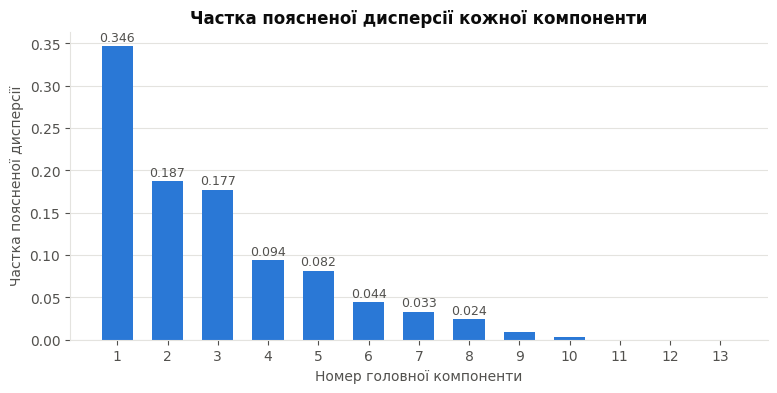

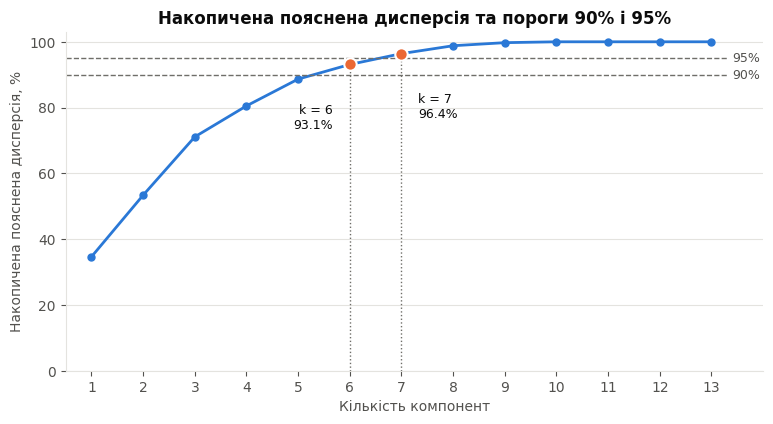

Показник,Увесь набір,Лише train (експеримент B)
Початкових ознак,13,13
Компонент для 90%,6,6
Компонент для 95%,7,7
Фактична накопичена дисперсія (90%),93.10%,93.21%
Фактична накопичена дисперсія (95%),96.40%,96.46%


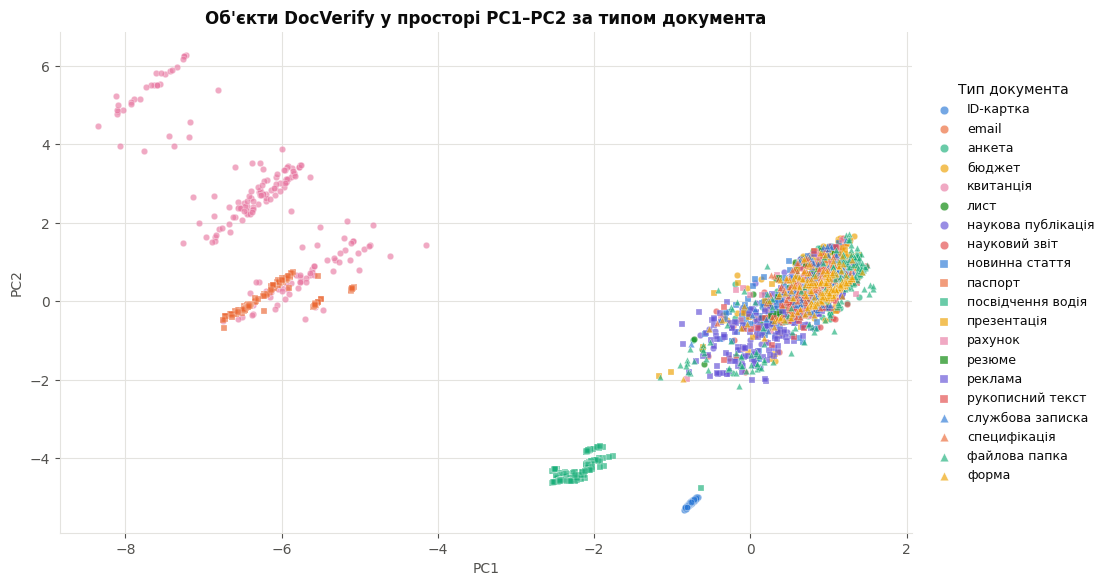

Модель,Робота,Test Accuracy,Test F1-macro,CV Accuracy (Лаб. №7)
k-NN (k=21),Лаб. №3,0.3962,0.4084,0.3786
GaussianNB,Лаб. №4,0.3297,0.3053,0.3229
Decision Tree (GridSearch),Лаб. №5,0.3677,0.3532,0.3542
Logistic Regression (C=1.0),Лаб. №6,0.3514,0.3293,0.3396


Критерій,Повний набір ознак,PCA
Accuracy,0.3962,0.3745
Precision (macro),0.4105,0.3902
Recall (macro),0.4213,0.3997
F1-score (macro),0.4084,0.3852
Weighted F1,0.3831,0.3596
Час навчання класифікатора,7.267 мс,2.966 мс
Час передбачення на test,60.897 мс,41.039 мс
Час навчання PCA (fit_transform train),—,0.843 мс
Час PCA-перетворення test,—,0.182 мс
Кількість ознак,13,6


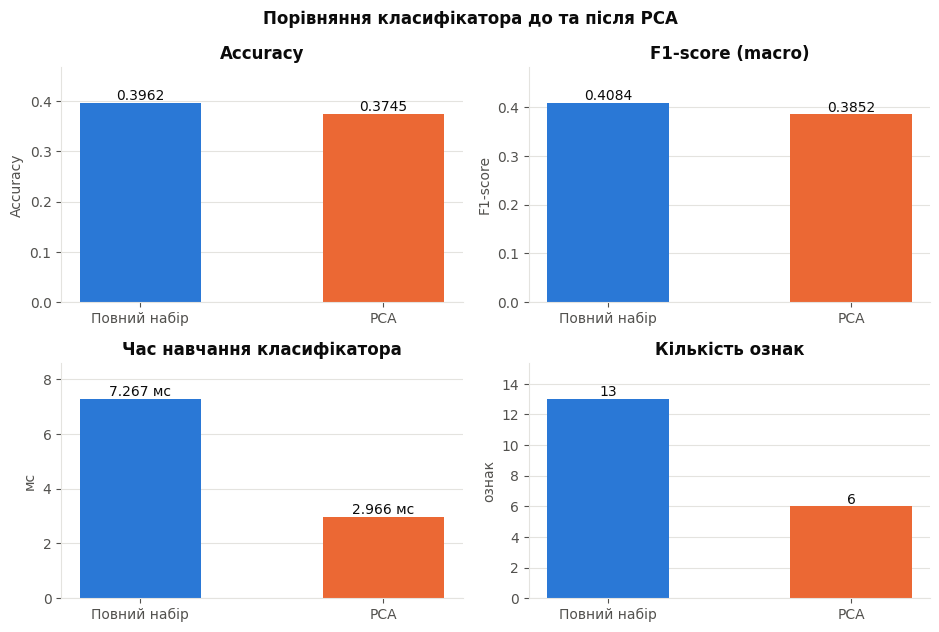

Показник,Зміна після PCA
Скорочення кількості ознак,53.8%
Зміна Accuracy,-2.17 в. п. (-5.5%)
Зміна F1-score,-2.33 в. п. (-5.7%)
Зміна часу навчання класифікатора,-59.2%
Зміна часу передбачення,-32.6%


In [9]:
STATES = {
    'idle': ('⏸', 'Очікування запуску', '#52514e', '#f1f0ec'),
    'running': ('⏳', 'Виконання аналізу', '#1c5cab', '#e4eefb'),
    'success': ('✔', 'Успішне завершення', '#006300', '#e3f3e3'),
    'insufficient': ('⚠', 'Недостатньо даних', '#8a5a00', '#fdf1d6'),
    'error': ('✖', 'Помилка обчислень', '#b3261e', '#fbe6e4'),
}


def status_html(state, detail=''):
    icon, label, color, background = STATES[state]
    return (f'<div style="padding:10px 14px;border-radius:6px;background:{background};color:{color};'
            f'max-width:880px"><b>{icon} {label}</b>'
            f'{"<br>" + escape(detail) if detail else ""}</div>')


def run_page(set_status, render):
    """Спільний сценарій кнопки та збереження звіту: кожен запуск дає рівно один фінальний стан."""
    set_status('running', 'Підготовка')
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', RuntimeWarning)   # NaN або ділення на 0 — це помилка
            result = run_analysis(progress=lambda message: set_status('running', message))
        render(result)
    except InsufficientDataError as error:
        set_status('insufficient', str(error))
    except Exception as error:
        set_status('error', f'{type(error).__name__}: {error}')
    else:
        cl = result['classification']
        set_status('success', f'Опрацьовано об\'єктів: {result["info"]["n_rows"]}. '
                              f'{cl["full"]["n_features"]} ознак → {cl["pca"]["n_features"]} компонент.')


display(HTML('<h2 style="margin-bottom:4px">Лабораторна робота №8 — Метод головних компонент (PCA)</h2>'
             '<h3 style="margin:14px 0 6px">1. Мета лабораторної роботи</h3>'
             '<p style="max-width:880px;line-height:1.5">Набути практичних навичок застосування PCA '
             'для зниження розмірності та візуалізації даних, дослідити частку поясненої дисперсії, '
             'порівняти якість і швидкодію класифікатора до та після зниження розмірності.</p>'))

if AUTO_RUN:
    status_handle = display(HTML(status_html('idle')), display_id=True)
    run_page(lambda state, detail='': status_handle.update(HTML(status_html(state, detail))),
             render_blocks)
else:
    status_view = widgets.HTML(status_html('idle', 'Натисніть «Запустити аналіз».'))
    run_button = widgets.Button(description='Запустити аналіз', button_style='primary', icon='play')
    report_output = widgets.Output()

    def show_status(state, detail=''):
        status_view.value = status_html(state, detail)

    def render_to_output(result):
        with report_output:
            render_blocks(result)

    def on_run_clicked(_):
        run_button.disabled = True
        report_output.clear_output()
        run_page(show_status, render_to_output)
        run_button.disabled = False

    run_button.on_click(on_run_clicked)
    display(widgets.VBox([run_button, status_view, report_output]))